In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

Для упрощения и сравнения игроков создал следующие фичи:

| Признак       | Способ создания            | Значение                                             |
|---------------|----------------------------|------------------------------------------------------|
| height_inches | Футы * 12 + дюймы          | Рост игрока в дюймах                                 |
| is_total      | Проверка Tm == "TOT"       | Технический признак суммарной записи игрока за сезон |
| PPG           | PTS / G                    | Среднее количество очков за матч                     |
| MPG           | MP / G                     | Среднее количество минут на площадке за матч         |
| Position      | Первая часть Pos до дефиса | Упрощённая категория игровой позиции                 |

Фича height_inches создается в первом датасете, остальные четыре в третьем. Признаки PPG и MPG рассчитываются только для записей с положительным количеством матчей. Для смешанных позиций использую первый указанный код, поэтому часть информации о позиции теряется.

In [3]:
# Разберем первый дата сет
df1 = pd.read_csv('player_data.csv')
df1.head()

,name,year_start,year_end,position,height,weight,birth_date,college
0,Alaa Abdelnaby,1991,1995,F-C,6-10,240.0,"June 24, 1968",Duke University
1,Zaid Abdul-Aziz,1969,1978,C-F,6-9,235.0,"April 7, 1946",Iowa State University
2,Kareem Abdul-Jabbar,1970,1989,C,7-2,225.0,"April 16, 1947","University of California, Los Angeles"
3,Mahmoud Abdul-Rauf,1991,2001,G,6-1,162.0,"March 9, 1969",Louisiana State University
4,Tariq Abdul-Wahad,1998,2003,F,6-6,223.0,"November 3, 1974",San Jose State University


In [4]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 4550 entries, 0 to 4549
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   name        4550 non-null   str    
 1   year_start  4550 non-null   int64  
 2   year_end    4550 non-null   int64  
 3   position    4549 non-null   str    
 4   height      4549 non-null   str    
 5   weight      4544 non-null   float64
 6   birth_date  4519 non-null   str    
 7   college     4248 non-null   str    
dtypes: float64(1), int64(2), str(5)
memory usage: 284.5 KB


In [5]:
# Поиск пропущенных значений
df1.isna().sum()

name            0
year_start      0
year_end        0
position        1
height          1
weight          6
birth_date     31
college       302
dtype: int64

In [6]:
# Поиск абсолютных дубликатов
df1.duplicated().sum()

np.int64(0)

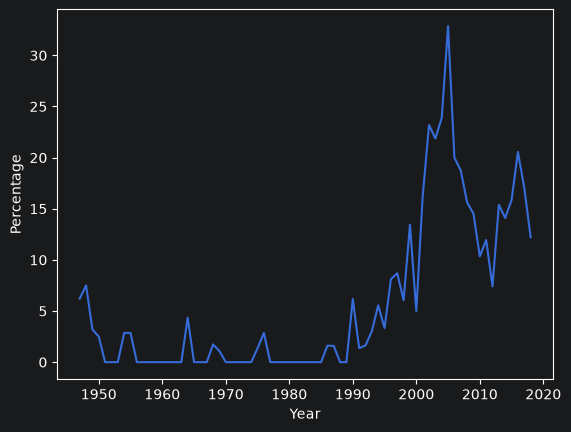

In [7]:
# Считаем среднее значение пропуска college у начинающий игроков
college_missing = df1['college'].isna().groupby(df1['year_start']).mean()
x, y = college_missing.index, college_missing.values * 100
plt.plot(x, y)
plt.xlabel('Year')
plt.ylabel('Percentage')
plt.show()

Линейный график показывает пропуски в сведениях о колледже, которые чаще встречаются у игроков, начавшие в поздние годы. Максимальная доля 32,9% на 2005 год.

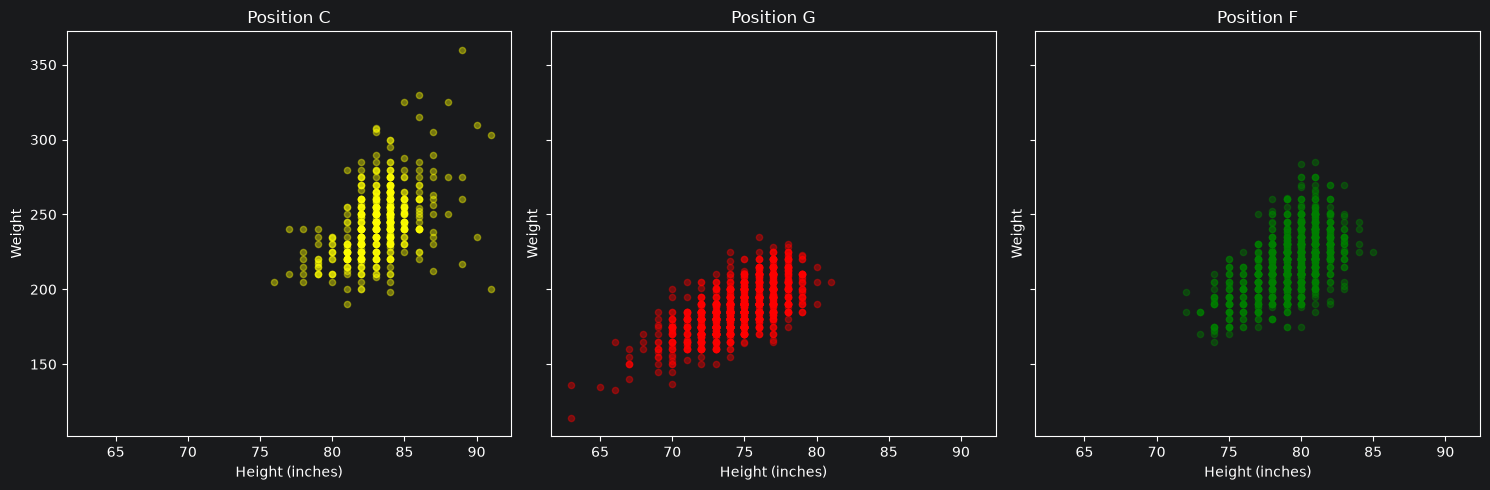

In [8]:
# Разделяем столбец на двое, футы и дюймы, переопределяем тип данных на float64, так как имеются пропуски
height_parts = df1['height'].str.split('-', expand=True).astype('float64')
# Переводим футы в дюймы и объединяем два столбца в один
height_inches = height_parts[0] * 12 + height_parts[1]
df1['height_inches'] = height_inches
# Фильтруем вес и рост игроков позиции С и строим график.
pos_c, pos_g, pos_f = df1[df1['position'] == 'C'], df1[df1['position'] == 'G'], df1[df1['position'] == 'F']

fig, ax = plt.subplots(1, 3, sharey=True, sharex=True, figsize=(15, 5))

# Диаграмма позиции C
ax[0].scatter(pos_c.height_inches, pos_c.weight, color='yellow', alpha=0.4, s=20)
ax[0].set_title('Position C')
ax[0].set_xlabel('Height (inches)')
ax[0].set_ylabel('Weight')

# Диаграмма позиции G
ax[1].scatter(pos_g.height_inches, pos_g.weight, color='red', alpha=0.4, s=20)
ax[1].set_title('Position G')
ax[1].set_xlabel('Height (inches)')
ax[1].set_ylabel('Weight')

# Диаграмма позиции F
ax[2].scatter(pos_f.height_inches, pos_f.weight, color='green', alpha=0.4, s=20)
ax[2].set_title('Position F')
ax[2].set_xlabel('Height (inches)')
ax[2].set_ylabel('Weight')

# Автоматическое выравнивание отступов
plt.tight_layout()

plt.show()

Диаграммы рассеяния показывает, что игроки позиции G обычно ниже и легче, C - выше и тяжелее, а F занимает промежуточное значение. Во всех группах большой рост связан с большим весом, но при одинаковом росте вес отличается.

In [9]:
# Разберем второй дата сет
df2 = pd.read_csv('Players.csv')
df2.head()

,Unnamed: 0,Player,height,weight,collage,born,birth_city,birth_state
0,0,Curly Armstrong,180.0,77.0,Indiana University,1918.0,NaN,NaN
1,1,Cliff Barker,188.0,83.0,University of Kentucky,1921.0,Yorktown,Indiana
2,2,Leo Barnhorst,193.0,86.0,University of Notre Dame,1924.0,NaN,NaN
3,3,Ed Bartels,196.0,88.0,North Carolina State University,1925.0,NaN,NaN
4,4,Ralph Beard,178.0,79.0,University of Kentucky,1927.0,Hardinsburg,Kentucky


In [10]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 3922 entries, 0 to 3921
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   3922 non-null   int64  
 1   Player       3921 non-null   str    
 2   height       3921 non-null   float64
 3   weight       3921 non-null   float64
 4   collage      3573 non-null   str    
 5   born         3921 non-null   float64
 6   birth_city   3452 non-null   str    
 7   birth_state  3439 non-null   str    
dtypes: float64(3), int64(1), str(4)
memory usage: 245.3 KB


In [11]:
# Поиск пропущенных значений
df2.isna().sum()

Unnamed: 0       0
Player           1
height           1
weight           1
collage        349
born             1
birth_city     470
birth_state    483
dtype: int64

In [12]:
# Поиск абсолютных дубликатов, исключая Unnamed: 0
cols = df2.columns.difference(['Unnamed: 0'])
df2.duplicated(subset=cols).sum()

np.int64(0)

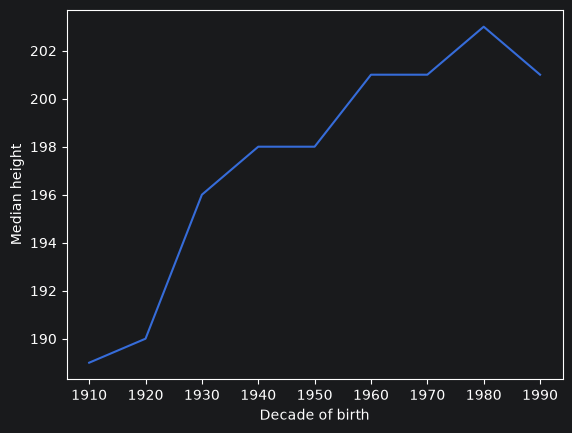

In [13]:
# Генерируем лист шагов для работы с десятилетиями.
bins = list(range(1910, 2001, 10))
labels = bins[:-1]
# Считаем медиану роста, группируем с десятилетиями.
md_height = df2['height'].groupby(pd.cut(df2['born'], bins=bins, labels=labels, right=False)).median()
x, y = md_height.index, md_height.values
plt.plot(x, y)
plt.xlabel('Decade of birth')
plt.ylabel('Median height')
plt.show()

Линейный график показывает, что медианный рост игроков увеличивается от разных поколений к более поздним, достигая максимума в 1980-х - 203 см. У поколения 1990-х снижается, до 201 см.

In [14]:
states = [
    "Alabama", "Alaska", "Arizona", "Arkansas",
    "California", "Colorado", "Connecticut", "Delaware", "District of Columbia",
    "Florida", "Georgia", "Hawaii",
    "Idaho", "Illinois", "Indiana", "Iowa", "Kansas", "Kentucky", "Louisiana",
    "Maine", "Maryland", "Massachusetts", "Michigan",
    "Minnesota", "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada",
    "New Hampshire", "New Jersey", "New Mexico", "New York", "North Carolina",
    "North Dakota", "Ohio", "Oklahoma", "Oregon",
    "Pennsylvania", "Rhode Island", "South Carolina",
    "South Dakota", "Tennessee", "Texas", "Utah", "Vermont",
    "Virginia", "Washington", "West Virginia", "Wisconsin", "Wyoming"
]
state_codes = {
    'Alabama': 'AL',
    'Alaska': 'AK',
    'American Samoa': 'AS',
    'Arizona': 'AZ',
    'Arkansas': 'AR',
    'California': 'CA',
    'Colorado': 'CO',
    'Connecticut': 'CT',
    'Delaware': 'DE',
    'District of Columbia': 'DC',
    'Federated States of Micronesia': 'FM',
    'Florida': 'FL',
    'Georgia': 'GA',
    'Guam': 'GU',
    'Hawaii': 'HI',
    'Idaho': 'ID',
    'Illinois': 'IL',
    'Indiana': 'IN',
    'Iowa': 'IA',
    'Kansas': 'KS',
    'Kentucky': 'KY',
    'Louisiana': 'LA',
    'Maine': 'ME',
    'Marshall Islands': 'MH',
    'Maryland': 'MD',
    'Massachusetts': 'MA',
    'Michigan': 'MI',
    'Minnesota': 'MN',
    'Mississippi': 'MS',
    'Missouri': 'MO',
    'Montana': 'MT',
    'Nebraska': 'NE',
    'Nevada': 'NV',
    'New Hampshire': 'NH',
    'New Jersey': 'NJ',
    'New Mexico': 'NM',
    'New York': 'NY',
    'North Carolina': 'NC',
    'North Dakota': 'ND',
    'Northern Mariana Islands': 'MP',
    'Ohio': 'OH',
    'Oklahoma': 'OK',
    'Oregon': 'OR',
    'Palau': 'PW',
    'Pennsylvania': 'PA',
    'Puerto Rico': 'PR',
    'Rhode Island': 'RI',
    'South Carolina': 'SC',
    'South Dakota': 'SD',
    'Tennessee': 'TN',
    'Texas': 'TX',
    'Utah': 'UT',
    'Vermont': 'VT',
    'Virgin Islands': 'VI',
    'Virginia': 'VA',
    'Washington': 'WA',
    'West Virginia': 'WV',
    'Wisconsin': 'WI',
    'Wyoming': 'WY'
}

# df2['birth_state'].isin(states)
count_states = df2[df2['birth_state'].isin(states)]['birth_state'].value_counts().reindex(states, fill_value=0)
# [state for state in states if state not in count_states]
codes = count_states.index.map(state_codes)
fig = px.choropleth(locations=codes,
                    color=count_states.values,
                    locationmode='USA-states',
                    scope='usa',
                    color_continuous_scale='Blues',
                    title='Количество игроков по штатам рождения',
                    labels={'color': 'Количество игроков', 'locations': 'Штат'},
                    hover_name=count_states.index
                    )
fig.show()

У 483 игроков поле birth_state не заполнено. На карте показаны только записи, сопоставленные с 50 штатами США и округом Колумбия.

In [15]:
# Рассмотрим третий дата сет
df3 = pd.read_csv('Seasons_Stats.csv')
df3.head()

,Unnamed: 0,Year,Player,Pos,Age,Tm,G,GS,MP,PER,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
0,0,1950.0,Curly Armstrong,G-F,31.0,FTW,63.0,NaN,NaN,NaN,...,0.705,NaN,NaN,NaN,176.0,NaN,NaN,NaN,217.0,458.0
1,1,1950.0,Cliff Barker,SG,29.0,INO,49.0,NaN,NaN,NaN,...,0.708,NaN,NaN,NaN,109.0,NaN,NaN,NaN,99.0,279.0
2,2,1950.0,Leo Barnhorst,SF,25.0,CHS,67.0,NaN,NaN,NaN,...,0.698,NaN,NaN,NaN,140.0,NaN,NaN,NaN,192.0,438.0
3,3,1950.0,Ed Bartels,F,24.0,TOT,15.0,NaN,NaN,NaN,...,0.559,NaN,NaN,NaN,20.0,NaN,NaN,NaN,29.0,63.0
4,4,1950.0,Ed Bartels,F,24.0,DNN,13.0,NaN,NaN,NaN,...,0.548,NaN,NaN,NaN,20.0,NaN,NaN,NaN,27.0,59.0


In [16]:
df3.info()

<class 'pandas.DataFrame'>
RangeIndex: 24691 entries, 0 to 24690
Data columns (total 53 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  24691 non-null  int64  
 1   Year        24624 non-null  float64
 2   Player      24624 non-null  str    
 3   Pos         24624 non-null  str    
 4   Age         24616 non-null  float64
 5   Tm          24624 non-null  str    
 6   G           24624 non-null  float64
 7   GS          18233 non-null  float64
 8   MP          24138 non-null  float64
 9   PER         24101 non-null  float64
 10  TS%         24538 non-null  float64
 11  3PAr        18839 non-null  float64
 12  FTr         24525 non-null  float64
 13  ORB%        20792 non-null  float64
 14  DRB%        20792 non-null  float64
 15  TRB%        21571 non-null  float64
 16  AST%        22555 non-null  float64
 17  STL%        20792 non-null  float64
 18  BLK%        20792 non-null  float64
 19  TOV%        19582 non-null  float64


In [17]:
# Поиск пропущенных значений
df3.isna().sum()

Unnamed: 0        0
Year             67
Player           67
Pos              67
Age              75
Tm               67
G                67
GS             6458
MP              553
PER             590
TS%             153
3PAr           5852
FTr             166
ORB%           3899
DRB%           3899
TRB%           3120
AST%           2136
STL%           3899
BLK%           3899
TOV%           5109
USG%           5051
blanl         24691
OWS             106
DWS             106
WS              106
WS/48           590
blank2        24691
OBPM           3894
DBPM           3894
BPM            3894
VORP           3894
FG               67
FGA              67
FG%             166
3P             5764
3PA            5764
3P%            9275
2P               67
2PA              67
2P%             195
eFG%            166
FT               67
FTA              67
FT%             925
ORB            3894
DRB            3894
TRB             379
AST              67
STL            3894
BLK            3894


In [18]:
# Поиск абсолютных дубликатов, исключая Unnamed: 0
cols = df3.columns.difference(['Unnamed: 0'])
df3.duplicated(subset=cols).sum()

np.int64(66)

Чистим дату и выбор одной записи на игрока за сезон

In [19]:
df3 = df3.dropna(subset=["Year", "Player"]).copy()
df3 = df3.drop(columns=["Unnamed: 0", "blanl", "blank2"], errors="ignore")
df3["Year"] = df3["Year"].astype(int)
df3["is_total"] = df3["Tm"].eq("TOT")
df3 = df3.sort_values("is_total", ascending=False)
df3 = df3.drop_duplicates(subset=["Year", "Player", "Age"]).copy()

# Делим сезонные суммы на кол-во сыгранных матчей
df3 = df3[df3["G"] > 0].copy()
df3["PPG"] = df3["PTS"] / df3["G"]
df3["MPG"] = df3["MP"] / df3["G"]

# Тут объявляю год и сезон глобально, для простаты работы
year = df3["Year"].max()
season = df3[(df3["Year"] == year) & (df3["G"] >= 30)].copy()

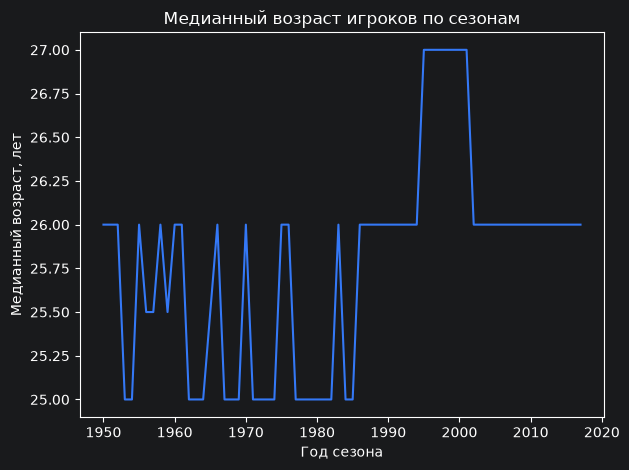

In [20]:
# Находим медианный возраст в каждом сезоне.
median_age = df3.dropna(subset=["Age"]).groupby("Year")["Age"].median()

plt.plot(median_age.index, median_age.values, color="#3478f6")
plt.title("Медианный возраст игроков по сезонам")
plt.xlabel("Год сезона")
plt.ylabel("Медианный возраст, лет")
plt.tight_layout()
plt.show()

Медианный возраст составлял 26 лет в 1950 и 26 лет в 2017 году. Данный линейный график показывает, как менялся типичный возраст игроков между сезонами.

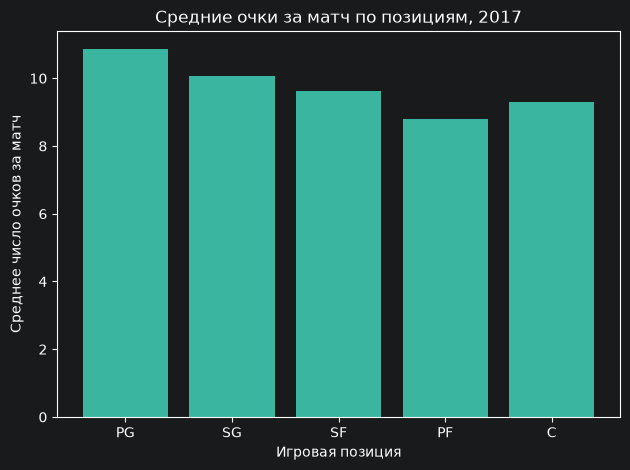

In [21]:
# Для смешанной позиции оставляем её первый код.
season["Position"] = season["Pos"].str.split("-").str[0]
points_by_pos = season.groupby("Position")["PPG"].mean()
points_by_pos = points_by_pos.reindex(["PG", "SG", "SF", "PF", "C"])

plt.bar(points_by_pos.index, points_by_pos.values, color="#39b5a0")
plt.title(f"Средние очки за матч по позициям, {year}")
plt.xlabel("Игровая позиция")
plt.ylabel("Среднее число очков за матч")
plt.tight_layout()
plt.show()

В этой выборке наибольшее среднее кол-во очков за матч у позиции PG составляет 10.85, наименьшее у PF составляет 8.80. Это средние по игрокам не менее чем 30 матчами

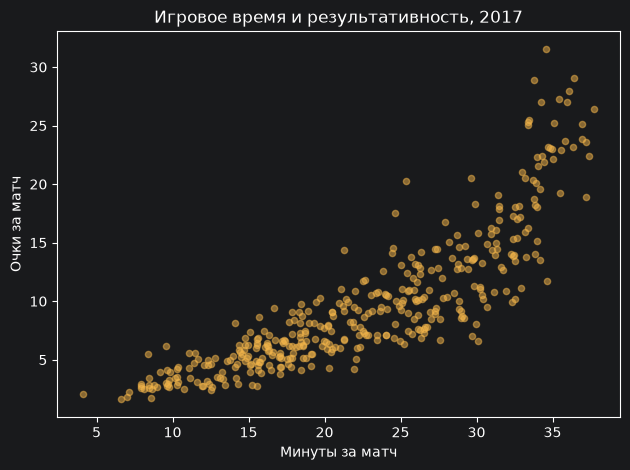

In [22]:
# Убираем пропуски только по двум нужным показателям.
scatter_data = season.dropna(subset=["MPG", "PPG"])

plt.scatter(scatter_data["MPG"], scatter_data["PPG"],
            color="#f3b54a", alpha=0.5, s=20)
plt.title(f"Игровое время и результативность, {year}")
plt.xlabel("Минуты за матч")
plt.ylabel("Очки за матч")
plt.tight_layout()
plt.show()

Облако точек судя по графику направлено вверх, больше минут связано с большим количеством очков. Коэффициент корреляции Пирсона равен 0.85, означает сильную положительную связь в этой выборке

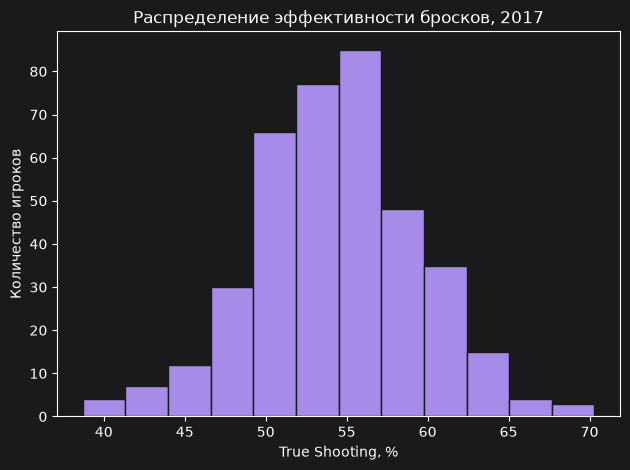

In [23]:
# Переводим TS из долей в проценты.
ts = season["TS%"].dropna() * 100

plt.hist(ts, bins=12, color="#a68be8", edgecolor="#181a1b")
plt.title(f"Распределение эффективности бросков, {year}")
plt.xlabel("True Shooting, %")
plt.ylabel("Количество игроков")
plt.tight_layout()
plt.show()

Медиана TS равна 54.3%. Центральные игроки 50% значений TS лежат примерно между 51% и 57.7%. Гистограмма показывает концентрацию значений в средний части и редкие значения.